# 01_Cek_Dataset


In [ ]:
# SEL 1 — Setup

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import os, gc, pickle, warnings
from tqdm import tqdm
warnings.filterwarnings('ignore')

BASE      = '/content/drive/MyDrive/dataset'
PROCESSED = f'{BASE}/processed'
os.makedirs(PROCESSED, exist_ok=True)

FILES = [
    f'{BASE}/log_standard_4_08_to_4_21_27k_part1.csv',
    f'{BASE}/log_standard_4_08_to_4_21_27k_part2.csv',
    f'{BASE}/log_standard_4_22_to_5_08_27k_part1.csv',
    f'{BASE}/log_standard_4_22_to_5_08_27k_part2.csv',
]

KOLOM = ['user_id','video_id','date','hourmin',
         'play_time_ms','is_like','is_comment','is_forward','is_hate']

# Parameter baru — berbasis interaksi, bukan waktu
N_USER        = 500   # jumlah user yang diambil
WIN_SIZE      = 10    # window = 10 interaksi berurutan
WIN_STEP      = 5     # geser 5 interaksi setiap window (overlap)
SEQ_LEN       = 8     # panjang sekuens input model
K_BURST       = 1.5   # threshold burst
MIN_WIN       = WIN_SIZE  # minimal interaksi per window

print("✅ Setup selesai!")
print(f"\nStrategi: Interaction-based window")
print(f"  Window size : {WIN_SIZE} interaksi")
print(f"  Window step : {WIN_STEP} interaksi")
print(f"  Seq length  : {SEQ_LEN} windows")

Mounted at /content/drive
✅ Setup selesai!

Strategi: Interaction-based window
  Window size : 10 interaksi
  Window step : 5 interaksi
  Seq length  : 8 windows


In [ ]:
# SEL 2 — Pilih User

CKPT_USER = f'{PROCESSED}/user_terpilih.pkl'

if os.path.exists(CKPT_USER):
    print("✅ Load user dari checkpoint...")
    with open(CKPT_USER,'rb') as f:
        user_terpilih = pickle.load(f)
    print(f"   {len(user_terpilih):,} user siap")

else:
    print("Scan user_id dari semua file...")
    semua_user = set()

    for filepath in FILES:
        print(f"  {os.path.basename(filepath)}")
        for chunk in pd.read_csv(
            filepath, usecols=['user_id'],
            chunksize=500_000, low_memory=False
        ):
            u = pd.to_numeric(chunk['user_id'], errors='coerce').dropna()
            semua_user.update(u.astype(int).tolist())
            del chunk
        gc.collect()

    np.random.seed(42)
    user_terpilih = set(np.random.choice(
        sorted(semua_user),
        size=min(N_USER, len(semua_user)),
        replace=False
    ))

    with open(CKPT_USER,'wb') as f:
        pickle.dump(user_terpilih, f)

    print(f"✅ {len(user_terpilih):,} user dipilih")

✅ Load user dari checkpoint...
   3,000 user siap


In [ ]:
# SEL 3 — Fungsi Proses Satu File
# Strategi baru: window berbasis urutan interaksi


def proses_file_interaksi(filepath, user_terpilih,
                           win_size, win_step,
                           k_burst, min_win):
    """
    Proses satu file dengan interaction-based windows.
    Tidak bergantung pada presisi timestamp.
    """
    nama = os.path.basename(filepath)

    # A: Baca baris user terpilih
    bagian = []
    for chunk in pd.read_csv(
        filepath, usecols=KOLOM,
        chunksize=200_000, low_memory=False
    ):
        chunk['user_id'] = pd.to_numeric(chunk['user_id'], errors='coerce')
        mask  = chunk['user_id'].isin(user_terpilih)
        baris = chunk[mask].copy()
        if len(baris) > 0:
            bagian.append(baris)
        del chunk, baris
        gc.collect()

    if not bagian:
        return pd.DataFrame()

    df = pd.concat(bagian, ignore_index=True)
    del bagian; gc.collect()

    # B: Bersihkan
    df = df.dropna(subset=['user_id','video_id','play_time_ms','date','hourmin'])
    df = df[df['play_time_ms'] > 0]
    for col in ['is_like','is_comment','is_forward','is_hate']:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)
        df      = df[df[col].isin([0,1])]
    df = df.drop_duplicates(subset=['user_id','date','hourmin','video_id'])

    if len(df) == 0:
        return pd.DataFrame()

    # C: Sort berdasarkan user, date, hourmin
    # Ini menggantikan timestamp — urutan interaksi yang penting
    df['date']    = pd.to_numeric(df['date'],    errors='coerce').fillna(0).astype(int)
    df['hourmin'] = pd.to_numeric(df['hourmin'], errors='coerce').fillna(0).astype(int)
    df = df.sort_values(
        ['user_id','date','hourmin']
    ).reset_index(drop=True)

    # D: Buat nomor urut interaksi per user
    df['urut_global'] = df.groupby('user_id').cumcount()

    # E: Definisi sesi = user + date + hour yang sama
    # Karena presisi data hanya per jam, sesi = 1 jam aktivitas
    df['jam']       = (df['hourmin'] // 100).astype(int)
    df['session_id']= (df['user_id'].astype(str) + '_' +
                       df['date'].astype(str)    + '_' +
                       df['jam'].astype(str))

    # F: Hitung intensity score per interaksi
    df['intensity'] = (
        df['play_time_ms'] / 1000 * 1.0 +
        df['is_like']              * 5.0 +
        df['is_comment']           * 10.0 +
        df['is_forward']           * 8.0 -
        df['is_hate']              * 3.0
    ).clip(lower=0)

    # G: Label impulsive per sesi (threshold per user)
    stats = df.groupby('user_id')['intensity'].agg(
        mean_u='mean', std_u='std'
    ).reset_index()
    stats['std_u']    = stats['std_u'].fillna(0)
    stats['thr_u']    = stats['mean_u'] + k_burst * stats['std_u']
    df = df.merge(stats[['user_id','thr_u']], on='user_id', how='left')
    df['impulsive']   = (df['intensity'] > df['thr_u']).astype(int)

    # H: Buat interaction-based windows per sesi
    windows = []

    for sid, sesi in df.groupby('session_id', sort=False):
        sesi = sesi.reset_index(drop=True)
        n    = len(sesi)
        uid  = sesi['user_id'].iloc[0]

        # Skip sesi yang terlalu pendek
        if n < win_size:
            continue

        # Geser window dengan langkah win_step
        start = 0
        urutan = 0

        while start + win_size <= n:
            w = sesi.iloc[start : start + win_size]

            if len(w) >= min_win:
                windows.append({
                    'session_id'  : sid,
                    'user_id'     : uid,
                    'urutan'      : urutan,
                    # Pakai index interaksi sebagai pengganti timestamp
                    'idx_start'   : start,
                    'n_total'     : len(w),
                    'n_like'      : int(w['is_like'].sum()),
                    'n_comment'   : int(w['is_comment'].sum()),
                    'n_forward'   : int(w['is_forward'].sum()),
                    'n_hate'      : int(w['is_hate'].sum()),
                    'avg_play_ms' : round(w['play_time_ms'].mean(), 2),
                    'avg_intens'  : round(w['intensity'].mean(), 2),
                    # Rasio engagement positif
                    'rasio_like'  : round(w['is_like'].mean(), 4),
                    'rasio_hate'  : round(w['is_hate'].mean(), 4),
                    # Label: ada interaksi impulsif dalam window ini?
                    'label'       : int(w['impulsive'].max()),
                })

            start  += win_step
            urutan += 1

    del df; gc.collect()
    return pd.DataFrame(windows)

print("✅ Fungsi siap!")

✅ Fungsi siap!


In [ ]:
# SEL 4 — Proses Semua File

PATH_WIN = f'{PROCESSED}/windows_interaksi.csv'
header_ok  = False
total_win  = 0

# Kalau sudah ada sebagian, hitung dulu
if os.path.exists(PATH_WIN):
    tmp = pd.read_csv(PATH_WIN, usecols=['label'])
    total_win  = len(tmp)
    header_ok  = True
    del tmp
    print(f"File windows sudah ada: {total_win:,} windows")

print("\nMemproses keempat file...\n")

for i, filepath in enumerate(FILES, 1):
    nama      = os.path.basename(filepath)
    ckpt_file = f'{PROCESSED}/win_file{i}.csv'

    if os.path.exists(ckpt_file):
        tmp = pd.read_csv(ckpt_file, usecols=['label'])
        print(f"[{i}/4] {nama} → sudah diproses ({len(tmp):,} windows)")
        del tmp
        continue

    print(f"[{i}/4] {nama}")
    print(f"       Memproses...")

    df_win = proses_file_interaksi(
        filepath      = filepath,
        user_terpilih = user_terpilih,
        win_size      = WIN_SIZE,
        win_step      = WIN_STEP,
        k_burst       = K_BURST,
        min_win       = MIN_WIN
    )

    if len(df_win) == 0:
        print(f"       ⚠️  Masih 0 windows dari file ini")
        # Simpan file kosong sebagai tanda sudah diproses
        pd.DataFrame(columns=['label']).to_csv(ckpt_file, index=False)
        continue

    # Simpan checkpoint per file
    df_win.to_csv(ckpt_file, index=False)

    # Append ke file gabungan
    df_win.to_csv(
        PATH_WIN, mode='a',
        header=not header_ok,
        index=False
    )
    header_ok  = True
    total_win += len(df_win)

    pct = df_win['label'].mean() * 100
    print(f"       ✅ {len(df_win):,} windows | {pct:.1f}% impulsif")
    print(f"       Total: {total_win:,} windows")

    del df_win; gc.collect()

print(f"\n{'='*50}")
print(f"SELESAI! Total windows: {total_win:,}")

File windows sudah ada: 4,527,175 windows

Memproses keempat file...

[1/4] log_standard_4_08_to_4_21_27k_part1.csv → sudah diproses (941,245 windows)
[2/4] log_standard_4_08_to_4_21_27k_part2.csv → sudah diproses (938,522 windows)
[3/4] log_standard_4_22_to_5_08_27k_part1.csv → sudah diproses (1,311,526 windows)
[4/4] log_standard_4_22_to_5_08_27k_part2.csv → sudah diproses (1,335,882 windows)

SELESAI! Total windows: 4,527,175


HASIL WINDOWS
Total windows  : 4,527,175
Total sesi     : 441,724
Total user     : 2,999
Label impulsif : 1,604,154 (35.43%)
Label normal   : 2,923,021

Kolom fitur:
['session_id', 'user_id', 'urutan', 'idx_start', 'n_total', 'n_like', 'n_comment', 'n_forward', 'n_hate', 'avg_play_ms', 'avg_intens', 'rasio_like', 'rasio_hate', 'label']

Sample data:
      session_id  user_id  urutan  idx_start  n_total  n_like  n_comment  \
0  6_20220408_12        6       0          0       10       0          0   
1  6_20220408_12        6       1          5       10       0          0   
2  6_20220408_13        6       0          0       10       0          0   
3  6_20220408_13        6       1          5       10       0          0   
4  6_20220408_13        6       2         10       10       0          0   
5  6_20220408_13        6       3         15       10       0          0   
6  6_20220408_13        6       4         20       10       0          0   
7  6_20220408_13        6       5       

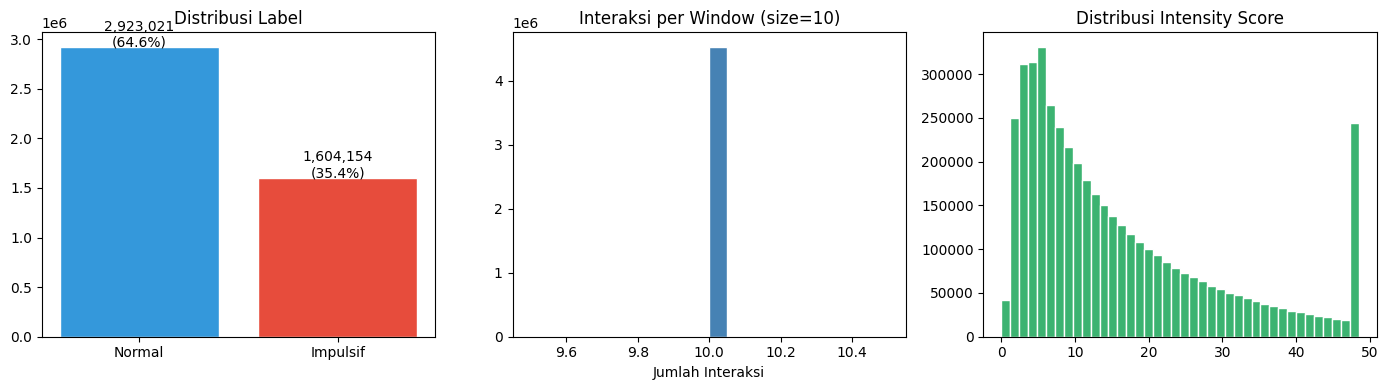

✅ Grafik tersimpan!


In [ ]:
# SEL 5 — Cek Hasil dan Validasi

df_win = pd.read_csv(PATH_WIN)

print("="*50)
print("HASIL WINDOWS")
print("="*50)
print(f"Total windows  : {len(df_win):,}")
print(f"Total sesi     : {df_win['session_id'].nunique():,}")
print(f"Total user     : {df_win['user_id'].nunique():,}")
print(f"Label impulsif : {df_win['label'].sum():,} ({df_win['label'].mean()*100:.2f}%)")
print(f"Label normal   : {(df_win['label']==0).sum():,}")

print(f"\nKolom fitur:")
print(df_win.columns.tolist())

print(f"\nSample data:")
print(df_win.head(10))

import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(14, 4))

counts = df_win['label'].value_counts()
ax[0].bar(['Normal','Impulsif'], counts.values,
          color=['#3498db','#e74c3c'], edgecolor='white')
ax[0].set_title('Distribusi Label')
for i,v in enumerate(counts.values):
    ax[0].text(i, v+5, f'{v:,}\n({v/len(df_win)*100:.1f}%)', ha='center')

ax[1].hist(df_win['n_total'], bins=20,
           color='steelblue', edgecolor='white')
ax[1].set_title(f'Interaksi per Window (size={WIN_SIZE})')
ax[1].set_xlabel('Jumlah Interaksi')

ax[2].hist(df_win['avg_intens'].clip(
    upper=df_win['avg_intens'].quantile(0.95)),
    bins=40, color='mediumseagreen', edgecolor='white')
ax[2].set_title('Distribusi Intensity Score')

plt.tight_layout()
plt.savefig(f'{PROCESSED}/ringkasan_windows.png', dpi=150)
plt.show()
print("✅ Grafik tersimpan!")

In [ ]:
# SEL 6 — Bentuk Sekuens

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

# Fitur behavioral
# intensity_norm DIHAPUS untuk mencegah direct leakage/circularity
FITUR = [
    'n_total',
    'n_like',
    'n_comment',
    'n_forward',
    'n_hate',
    'avg_play_ms',
    'rasio_like'
]

print(f"Membentuk sekuens (panjang={SEQ_LEN})...")

X_list, y_list, T_list = [], [], []

for sid, grup in tqdm(
    df_win.groupby('session_id'),
    desc="Sekuens"
):
    grup = grup.sort_values(
        'urutan'
    ).reset_index(drop=True)

    if len(grup) < SEQ_LEN + 1:
        continue

    for i in range(len(grup) - SEQ_LEN):

        X_list.append(
            grup[FITUR]
            .iloc[i:i+SEQ_LEN]
            .values
        )

        T_list.append(
            grup['idx_start']
            .iloc[i:i+SEQ_LEN]
            .values
        )

        y_list.append(
            grup['label']
            .iloc[i+SEQ_LEN]
        )

X = np.array(
    X_list,
    dtype=np.float32
)

T = np.array(
    T_list,
    dtype=np.float32
)

y = np.array(
    y_list,
    dtype=np.float32
)

print("\n✅ Sekuens terbentuk!")
print(f"   Total sampel : {X.shape[0]:,}")
print(f"   Shape X      : {X.shape}")
print(f"   % impulsif   : {y.mean()*100:.2f}%")

if X.shape[0] < 100:
    print("\n⚠️  Sampel masih terlalu sedikit!")
    print("   Coba naikkan N_USER di SEL 1 menjadi 1000")
    print("   atau turunkan WIN_SIZE menjadi 5")
else:
    print("\n✅ Sampel cukup untuk training!")

# Split 70/15/15
X_tr,X_tmp,y_tr,y_tmp,T_tr,T_tmp = train_test_split(
    X,y,T, test_size=0.30, random_state=42, stratify=y
)
X_val,X_te,y_val,y_te,T_val,T_te = train_test_split(
    X_tmp,y_tmp,T_tmp, test_size=0.50, random_state=42, stratify=y_tmp
)

N,S,F  = X_tr.shape
scaler = StandardScaler()
X_tr_n = scaler.fit_transform(X_tr.reshape(-1,F)).reshape(N,S,F)
X_val_n= scaler.transform(X_val.reshape(-1,F)).reshape(len(X_val),S,F)
X_te_n = scaler.transform(X_te.reshape(-1,F)).reshape(len(X_te),S,F)

# Normalisasi T (posisi relatif dari window pertama)
T_tr_n  = T_tr  - T_tr[:,0:1]
T_val_n = T_val - T_val[:,0:1]
T_te_n  = T_te  - T_te[:,0:1]

bobot = compute_class_weight('balanced', classes=np.array([0,1]), y=y_tr)
pos_w = float(bobot[1]/bobot[0])

print(f"\nSplit:")
print(f"  Train : {len(X_tr_n):,}  ({y_tr.mean()*100:.1f}% impulsif)")
print(f"  Val   : {len(X_val_n):,}   ({y_val.mean()*100:.1f}% impulsif)")
print(f"  Test  : {len(X_te_n):,}   ({y_te.mean()*100:.1f}% impulsif)")
print(f"  Pos weight: {pos_w:.2f}")

with open(f'{PROCESSED}/data_training.pkl','wb') as f:
    pickle.dump({
        'X_tr':X_tr_n,'y_tr':y_tr,'T_tr':T_tr_n,
        'X_val':X_val_n,'y_val':y_val,'T_val':T_val_n,
        'X_te':X_te_n,'y_te':y_te,'T_te':T_te_n,
        'pos_w':pos_w,'scaler':scaler,'fitur': FITUR
    },f)
print("✅ Data training tersimpan!")

Membentuk sekuens (panjang=8)...


Sekuens: 100%|██████████| 441724/441724 [22:53<00:00, 321.67it/s]



✅ Sekuens terbentuk!
   Total sampel : 2,166,790
   Shape X      : (2166790, 8, 7)
   % impulsif   : 26.55%

✅ Sampel cukup untuk training!

Split:
  Train : 1,516,753  (26.6% impulsif)
  Val   : 325,018   (26.6% impulsif)
  Test  : 325,019   (26.6% impulsif)
  Pos weight: 2.77
✅ Data training tersimpan!


In [ ]:
import pickle

PROCESSED = '/content/drive/MyDrive/dataset/processed'

with open(f'{PROCESSED}/data_training.pkl','rb') as f:
    d = pickle.load(f)

print(f"Train  : {len(d['X_tr']):,} sampel")
print(f"Val    : {len(d['X_val']):,} sampel")
print(f"Test   : {len(d['X_te']):,} sampel")
print(f"Shape  : {d['X_tr'].shape}")
print(f"Pos w  : {d['pos_w']:.2f}")

Train  : 1,516,753 sampel
Val    : 325,018 sampel
Test   : 325,019 sampel
Shape  : (1516753, 8, 7)
Pos w  : 2.77


In [ ]:
# SEL 7 — Subsample + Training

import torch
import torch.nn as nn
import numpy as np
import pickle
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import roc_auc_score, f1_score, classification_report

PROCESSED = '/content/drive/MyDrive/dataset/processed'
device    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
if device.type == 'cpu':
    print("⚠️  GPU tidak aktif!")
    print("   Klik Runtime → Change runtime type → T4 GPU → Save")
    print("   Lalu jalankan ulang sel ini")

# ---- Load data ----
with open(f'{PROCESSED}/data_training.pkl','rb') as f:
    d = pickle.load(f)

N_TRAIN = 80_000
N_VAL   = 15_000
N_TEST  = 15_000

def subsample(X, y, T, n, seed=42):
    """Ambil n sampel dengan distribusi label yang sama (stratified)."""
    rng    = np.random.default_rng(seed)
    idx0   = np.where(y == 0)[0]
    idx1   = np.where(y == 1)[0]

    # Hitung proporsi
    r1     = y.mean()
    n1     = min(int(n * r1), len(idx1))
    n0     = min(n - n1, len(idx0))

    chosen = np.concatenate([
        rng.choice(idx0, size=n0, replace=False),
        rng.choice(idx1, size=n1, replace=False)
    ])
    rng.shuffle(chosen)
    return X[chosen], y[chosen], T[chosen]

X_tr,  y_tr,  T_tr  = subsample(d['X_tr'],  d['y_tr'],  d['T_tr'],  N_TRAIN)
X_val, y_val, T_val = subsample(d['X_val'], d['y_val'], d['T_val'], N_VAL)
X_te,  y_te,  T_te  = subsample(d['X_te'],  d['y_te'],  d['T_te'],  N_TEST)

print(f"\n✅ Subsample selesai!")
print(f"   Train : {len(X_tr):,}  ({y_tr.mean()*100:.1f}% impulsif)")
print(f"   Val   : {len(X_val):,}  ({y_val.mean()*100:.1f}% impulsif)")
print(f"   Test  : {len(X_te):,}  ({y_te.mean()*100:.1f}% impulsif)")

# ---- Konversi ke tensor ----
def tt(a): return torch.tensor(a, dtype=torch.float32)

X_tr_t  = tt(X_tr);  y_tr_t  = tt(y_tr);  T_tr_t  = tt(T_tr)
X_val_t = tt(X_val); y_val_t = tt(y_val); T_val_t = tt(T_val)
X_te_t  = tt(X_te);  y_te_t  = tt(y_te);  T_te_t  = tt(T_te)

# ---- DataLoader ----
BATCH = 256   # lebih besar = lebih cepat per epoch
tr_dl = DataLoader(TensorDataset(X_tr_t,y_tr_t,T_tr_t),
                   batch_size=BATCH, shuffle=True,
                   num_workers=2, pin_memory=True)
vl_dl = DataLoader(TensorDataset(X_val_t,y_val_t,T_val_t),
                   batch_size=BATCH, shuffle=False,
                   num_workers=2, pin_memory=True)

print(f"\n   Batch size     : {BATCH}")
print(f"   Iterasi/epoch  : {len(tr_dl):,}")
print(f"   Estimasi waktu : ~{len(tr_dl)*0.015/60:.1f} menit per epoch (GPU)")

Device: cuda

✅ Subsample selesai!
   Train : 80,000  (26.6% impulsif)
   Val   : 15,000  (26.5% impulsif)
   Test  : 15,000  (26.5% impulsif)

   Batch size     : 256
   Iterasi/epoch  : 313
   Estimasi waktu : ~0.1 menit per epoch (GPU)


In [ ]:
# Sel 8 - TIAT: LEAKAGE-REDUCED VERSION

class TimeIntensityAttention(nn.Module):

    def __init__(self, d_model, n_heads):
        super().__init__()

        self.n_heads = n_heads
        self.d_head  = d_model // n_heads
        self.d_model = d_model

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

        # Learnable temporal and intensity weights
        self.lam   = nn.Parameter(torch.tensor(0.1))
        self.gamma = nn.Parameter(torch.tensor(0.1))

        self.drop = nn.Dropout(0.1)

    def forward(self, x, timestamps, intensity):

        B, S, _ = x.shape

        Q = self.W_q(x).view(
            B, S, self.n_heads, self.d_head
        ).transpose(1, 2)

        K = self.W_k(x).view(
            B, S, self.n_heads, self.d_head
        ).transpose(1, 2)

        V = self.W_v(x).view(
            B, S, self.n_heads, self.d_head
        ).transpose(1, 2)

        # Standard attention score

        score = torch.matmul(
            Q,
            K.transpose(-2, -1)
        ) / (self.d_head ** 0.5)

        # Relative temporal position bias

        t = timestamps.unsqueeze(2)

        t_diff = torch.abs(
            t - t.transpose(1, 2)
        )

        t_diff = t_diff / (
            t_diff.max() + 1e-8
        )

        score = (
            score
            - self.lam.abs()
            * t_diff
            .unsqueeze(1)
        )

        # Learned behavioral intensity bias

        score = (
            score
            + self.gamma.abs()
            * intensity
            .unsqueeze(1)
            .unsqueeze(2)
        )

        attn = self.drop(
            torch.softmax(
                score,
                dim=-1
            )
        )

        out = torch.matmul(
            attn,
            V
        )

        out = (
            out
            .transpose(1, 2)
            .contiguous()
            .view(B, S, self.d_model)
        )

        return self.W_o(out), attn


class TIAT(nn.Module):

    def __init__(
        self,
        n_fitur=7,
        d_model=32,
        n_heads=4,
        n_layers=1,
        seq_len=8,
        dropout=0.1
    ):

        super().__init__()

        # Input projection

        self.input_proj = nn.Linear(
            n_fitur,
            d_model
        )

        self.pos_embed = nn.Embedding(
            seq_len,
            d_model
        )

        # Learn behavioral intensity

        self.intensity_proj = nn.Linear(
            d_model,
            1
        )

        self.attn_layers = nn.ModuleList([
            TimeIntensityAttention(
                d_model,
                n_heads
            )
            for _ in range(n_layers)
        ])

        self.ff_layers = nn.ModuleList([
            nn.Sequential(
                nn.Linear(
                    d_model,
                    d_model * 2
                ),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(
                    d_model * 2,
                    d_model
                )
            )
            for _ in range(n_layers)
        ])

        self.norms = nn.ModuleList([
            nn.LayerNorm(d_model)
            for _ in range(n_layers)
        ])

        self.clf = nn.Sequential(
            nn.Linear(d_model, 16),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(16, 1)
        )

    def forward(self, x, t):

        B, S, _ = x.shape

        # Behavioral representation

        x = (
            self.input_proj(x)
            + self.pos_embed(
                torch.arange(
                    S,
                    device=x.device
                ).unsqueeze(0)
            )
        )

        # Learn intensity representation

        intensity = torch.sigmoid(
            self.intensity_proj(x)
        ).squeeze(-1)

        # TIAT layers

        for attn, ff, norm in zip(
            self.attn_layers,
            self.ff_layers,
            self.norms
        ):

            a_out, _ = attn(
                x,
                t,
                intensity
            )

            x = norm(
                x + a_out
            )

            x = norm(
                x + ff(x)
            )

        # Predict next interaction window

        return self.clf(
            x[:, -1, :]
        ).squeeze(-1)


# INIT MODEL

SEQ_LEN = 8

model = TIAT(
    n_fitur=7,
    d_model=32,
    n_heads=4,
    n_layers=1,
    seq_len=SEQ_LEN
).to(device)

n_param = sum(
    p.numel()
    for p in model.parameters()
)

print("\n✅ Leakage-reduced TIAT siap!")
print(f"   Parameter : {n_param:,}")
print(
    f"   λ awal    : "
    f"{model.attn_layers[0].lam.item():.3f}"
)
print(
    f"   γ awal    : "
    f"{model.attn_layers[0].gamma.item():.3f}"
)


✅ Leakage-reduced TIAT siap!
   Parameter : 9,572
   λ awal    : 0.100
   γ awal    : 0.100


In [ ]:
# Sel 9 - TRAINING TIAT: LEAKAGE-REDUCED VERSION

loss_fn = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [d['pos_w']],
        dtype=torch.float32
    ).to(device)
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',
    patience=3,
    factor=0.5
)

N_EPOCH = 30

best_auc = 0.0
best_wts = None
log = []

print("=" * 55)
print("TRAINING TIAT — LEAKAGE-REDUCED")
print("=" * 55)
print(f"Epoch     : {N_EPOCH}")
print(f"Batch     : {BATCH}")
print(f"Train set : {len(X_tr):,} sampel")
print(f"Val set   : {len(X_val):,} sampel")
print("=" * 55)


# EPOCH LOOP

for ep in range(1, N_EPOCH + 1):

    # TRAINING

    model.train()

    total_loss = 0.0

    for Xb, yb, Tb in tr_dl:

        Xb = Xb.to(
            device,
            non_blocking=True
        )

        yb = yb.to(
            device,
            non_blocking=True
        )

        Tb = Tb.to(
            device,
            non_blocking=True
        )

        # Reset gradient
        optimizer.zero_grad()

        logits = model(
            Xb,
            Tb
        )

        loss = loss_fn(
            logits,
            yb
        )

        # Backpropagation
        loss.backward()

        # Prevent exploding gradients
        nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()


    # AVERAGE TRAINING LOSS

    avg_loss = (
        total_loss /
        len(tr_dl)
    )


    # VALIDATION

    model.eval()

    probs = []
    trues = []

    with torch.no_grad():

        for Xb, yb, Tb in vl_dl:

            Xb = Xb.to(
                device,
                non_blocking=True
            )

            yb = yb.to(
                device,
                non_blocking=True
            )

            Tb = Tb.to(
                device,
                non_blocking=True
            )

            # Forward pass

            logits = model(
                Xb,
                Tb
            )

            probabilities = torch.sigmoid(
                logits
            )

            probs.extend(
                probabilities
                .cpu()
                .numpy()
            )

            trues.extend(
                yb
                .cpu()
                .numpy()
            )


    # VALIDATION AUC

    val_auc = roc_auc_score(
        trues,
        probs
    )


    # LR SCHEDULER

    scheduler.step(
        val_auc
    )


    # CHECK BEST MODEL

    tanda = ""

    if val_auc > best_auc:

        best_auc = val_auc

        best_wts = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }

        # Save best model
        torch.save(
            best_wts,
            f'{PROCESSED}/tiat_model.pth'
        )

        tanda = " ← TERBAIK (disimpan)"


    # SAVE LOG

    log.append({
        'ep': ep,
        'loss': avg_loss,
        'auc': val_auc
    })


    # PRINT PROGRESS

    print(
        f"Epoch {ep:2d}/{N_EPOCH} | "
        f"Loss: {avg_loss:.4f} | "
        f"AUC: {val_auc:.4f}"
        f"{tanda}"
    )


# TRAINING FINISHED

print("\n" + "=" * 55)
print("✅ TRAINING SELESAI!")
print("=" * 55)

print(
    f"AUC terbaik: {best_auc:.4f}"
)

print(
    f"Model terbaik disimpan di:"
)

print(
    f"{PROCESSED}/tiat_model.pth"
)

TRAINING TIAT — LEAKAGE-REDUCED
Epoch     : 30
Batch     : 256
Train set : 80,000 sampel
Val set   : 15,000 sampel
Epoch  1/30 | Loss: 0.8687 | AUC: 0.7760 ← TERBAIK (disimpan)
Epoch  2/30 | Loss: 0.8366 | AUC: 0.7817 ← TERBAIK (disimpan)
Epoch  3/30 | Loss: 0.8315 | AUC: 0.7861 ← TERBAIK (disimpan)
Epoch  4/30 | Loss: 0.8262 | AUC: 0.7864 ← TERBAIK (disimpan)
Epoch  5/30 | Loss: 0.8256 | AUC: 0.7864 ← TERBAIK (disimpan)
Epoch  6/30 | Loss: 0.8222 | AUC: 0.7902 ← TERBAIK (disimpan)
Epoch  7/30 | Loss: 0.8216 | AUC: 0.7889
Epoch  8/30 | Loss: 0.8215 | AUC: 0.7891
Epoch  9/30 | Loss: 0.8208 | AUC: 0.7892
Epoch 10/30 | Loss: 0.8190 | AUC: 0.7896
Epoch 11/30 | Loss: 0.8164 | AUC: 0.7925 ← TERBAIK (disimpan)
Epoch 12/30 | Loss: 0.8160 | AUC: 0.7907
Epoch 13/30 | Loss: 0.8166 | AUC: 0.7921
Epoch 14/30 | Loss: 0.8155 | AUC: 0.7914
Epoch 15/30 | Loss: 0.8142 | AUC: 0.7928 ← TERBAIK (disimpan)
Epoch 16/30 | Loss: 0.8145 | AUC: 0.7933 ← TERBAIK (disimpan)
Epoch 17/30 | Loss: 0.8163 | AUC: 0.7934

HASIL AKHIR — TEST SET
AUC-ROC  : 0.7890
PR-AUC   : 0.6119
F1-Score : 0.5754

Classification Report:
              precision    recall  f1-score   support

      Normal       0.86      0.76      0.81     11018
    Impulsif       0.51      0.67      0.58      3982

    accuracy                           0.74     15000
   macro avg       0.68      0.72      0.69     15000
weighted avg       0.77      0.74      0.75     15000


Parameter yang dipelajari model:
  λ (time bias)      : 1.0545
  γ (intensity bias) : 0.0334


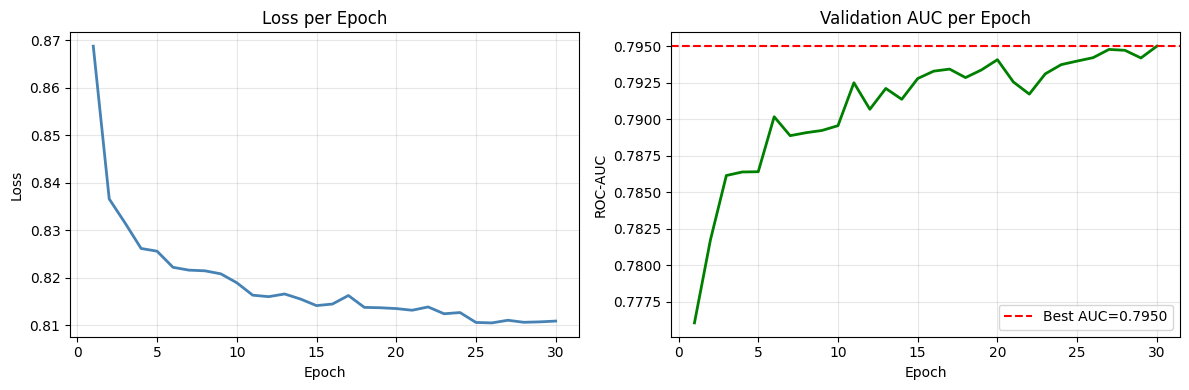

✅ Grafik hasil tersimpan!


In [ ]:
# Sel 10 - EVALUASI FINAL TEST SET

from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    average_precision_score,
    classification_report
)

# Load best model

model.load_state_dict(best_wts)
model.eval()


# Prediction

with torch.no_grad():

    Xd = X_te_t.to(device)
    Td = T_te_t.to(device)

    prob_te = torch.sigmoid(
        model(Xd, Td)
    ).cpu().numpy()


# True label & predicted label

y_true = y_te_t.numpy()

pred_te = (
    prob_te >= 0.5
).astype(int)


# Evaluation metrics

# ROC-AUC
auc_te = roc_auc_score(
    y_true,
    prob_te
)

# PR-AUC
pr_auc_te = average_precision_score(
    y_true,
    prob_te
)

# F1-Score
f1_te = f1_score(
    y_true,
    pred_te,
    zero_division=0
)


# Classification report

print("=" * 55)
print("HASIL AKHIR — TEST SET")
print("=" * 55)

print(
    f"AUC-ROC  : {auc_te:.4f}"
)

print(
    f"PR-AUC   : {pr_auc_te:.4f}"
)

print(
    f"F1-Score : {f1_te:.4f}"
)

print(
    "\nClassification Report:"
)

print(
    classification_report(
        y_true,
        pred_te,
        target_names=[
            'Normal',
            'Impulsif'
        ],
        zero_division=0
    )
)


# Learned parameters

print(
    "\nParameter yang dipelajari model:"
)

print(
    f"  λ (time bias)      : "
    f"{model.attn_layers[0].lam.item():.4f}"
)

print(
    f"  γ (intensity bias) : "
    f"{model.attn_layers[0].gamma.item():.4f}"
)


# GRAFIK TRAINING

fig, ax = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)


# Loss

ax[0].plot(
    [x['ep'] for x in log],
    [x['loss'] for x in log],
    color='steelblue',
    lw=2
)

ax[0].set_title(
    'Loss per Epoch'
)

ax[0].set_xlabel(
    'Epoch'
)

ax[0].set_ylabel(
    'Loss'
)

ax[0].grid(
    alpha=0.3
)


# Validation AUC

ax[1].plot(
    [x['ep'] for x in log],
    [x['auc'] for x in log],
    color='green',
    lw=2
)

ax[1].axhline(
    best_auc,
    color='red',
    ls='--',
    label=f'Best AUC={best_auc:.4f}'
)

ax[1].set_title(
    'Validation AUC per Epoch'
)

ax[1].set_xlabel(
    'Epoch'
)

ax[1].set_ylabel(
    'ROC-AUC'
)

ax[1].legend()

ax[1].grid(
    alpha=0.3
)


# Save & show

plt.tight_layout()

plt.savefig(
    f'{PROCESSED}/hasil_training.png',
    dpi=150
)

plt.show()

print(
    "✅ Grafik hasil tersimpan!"
)

In [ ]:
# Sel 11 — PERSIAPAN BASELINE MODEL

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

print("=" * 60)
print("PERSIAPAN PERBANDINGAN MODEL")
print("=" * 60)

print(f"Train : {X_tr.shape}")
print(f"Val   : {X_val.shape}")
print(f"Test  : {X_te.shape}")

print(f"\nDistribusi label test:")
print(f"Normal   : {(y_te == 0).sum():,}")
print(f"Impulsif : {(y_te == 1).sum():,}")
print(f"Impulsif: {y_te.mean()*100:.2f}%")

X_tr_flat = X_tr.reshape(len(X_tr), -1)
X_val_flat = X_val.reshape(len(X_val), -1)
X_te_flat = X_te.reshape(len(X_te), -1)

print("\nShape setelah flatten:")
print("Train:", X_tr_flat.shape)
print("Val  :", X_val_flat.shape)
print("Test :", X_te_flat.shape)

# Fungsi evaluasi umum

hasil_model = {}

def evaluasi_model(nama, y_true, prob):

    pred = (prob >= 0.5).astype(int)

    acc = accuracy_score(y_true, pred)
    prec = precision_score(
        y_true, pred, zero_division=0
    )
    rec = recall_score(
        y_true, pred, zero_division=0
    )
    f1 = f1_score(
        y_true, pred, zero_division=0
    )
    auc = roc_auc_score(
        y_true, prob
    )
    pr_auc = average_precision_score(
        y_true, prob
    )

    hasil_model[nama] = {
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1": f1,
        "ROC-AUC": auc,
        "PR-AUC": pr_auc
    }

    print("\n" + "=" * 60)
    print(nama)
    print("=" * 60)

    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1       : {f1:.4f}")
    print(f"ROC-AUC  : {auc:.4f}")
    print(f"PR-AUC   : {pr_auc:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            y_true,
            pred,
            target_names=["Normal", "Impulsif"],
            zero_division=0
        )
    )

    return pred

PERSIAPAN PERBANDINGAN MODEL
Train : (80000, 8, 7)
Val   : (15000, 8, 7)
Test  : (15000, 8, 7)

Distribusi label test:
Normal   : 11,018
Impulsif : 3,982
Impulsif: 26.55%

Shape setelah flatten:
Train: (80000, 56)
Val  : (15000, 56)
Test : (15000, 56)


In [ ]:
# Sel 12 — LOGISTIC REGRESSION + XGBOOST

from sklearn.linear_model import LogisticRegression

print("=" * 60)
print("MODEL 1 — LOGISTIC REGRESSION")
print("=" * 60)

# Logistic Regression

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

lr_model.fit(
    X_tr_flat,
    y_tr
)

prob_lr = lr_model.predict_proba(
    X_te_flat
)[:, 1]

pred_lr = evaluasi_model(
    "Logistic Regression",
    y_te,
    prob_lr
)

# XGBOOST

print("\n" + "=" * 60)
print("MODEL 2 — XGBOOST")
print("=" * 60)

try:

    from xgboost import XGBClassifier

    # Rasio kelas untuk menangani imbalance
    n_normal = (y_tr == 0).sum()
    n_impulsif = (y_tr == 1).sum()

    scale_pos = n_normal / max(n_impulsif, 1)

    xgb_model = XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="auc",
        scale_pos_weight=scale_pos,
        random_state=42,
        n_jobs=-1
    )

    xgb_model.fit(
        X_tr_flat,
        y_tr,
        eval_set=[(X_val_flat, y_val)],
        verbose=False
    )

    prob_xgb = xgb_model.predict_proba(
        X_te_flat
    )[:, 1]

    pred_xgb = evaluasi_model(
        "XGBoost",
        y_te,
        prob_xgb
    )

except ImportError:

    print("""
    XGBoost belum terinstall.

    Jalankan:

    !pip install -q xgboost

    lalu jalankan kembali SEL 14.
    """)

MODEL 1 — LOGISTIC REGRESSION

Logistic Regression
Accuracy : 0.7377
Precision: 0.5051
Recall   : 0.5964
F1       : 0.5470
ROC-AUC  : 0.7558
PR-AUC   : 0.5414

Classification Report:
              precision    recall  f1-score   support

      Normal       0.84      0.79      0.82     11018
    Impulsif       0.51      0.60      0.55      3982

    accuracy                           0.74     15000
   macro avg       0.67      0.69      0.68     15000
weighted avg       0.75      0.74      0.74     15000


MODEL 2 — XGBOOST

XGBoost
Accuracy : 0.7288
Precision: 0.4921
Recall   : 0.6733
F1       : 0.5686
ROC-AUC  : 0.7850
PR-AUC   : 0.6019

Classification Report:
              precision    recall  f1-score   support

      Normal       0.86      0.75      0.80     11018
    Impulsif       0.49      0.67      0.57      3982

    accuracy                           0.73     15000
   macro avg       0.68      0.71      0.69     15000
weighted avg       0.77      0.73      0.74     15000



In [ ]:
# Sel 13 — STANDARD TRANSFORMER
# LEAKAGE-REDUCED + VALIDATION-BASED MODEL SELECTION

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    classification_report
)

print("=" * 60)
print("MODEL 3 — STANDARD TRANSFORMER")
print("=" * 60)


# 1. DEVICE

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# 2. CHECK FEATURE DIMENSION

N_FEATURES = X_tr.shape[-1]

print("Number of input features:", N_FEATURES)

assert N_FEATURES == 7, (
    f"Expected 7 features, but found {N_FEATURES}"
)


# 3. TENSOR

Xtr_tensor = torch.tensor(
    X_tr,
    dtype=torch.float32
)

ytr_tensor = torch.tensor(
    y_tr,
    dtype=torch.float32
)

Xval_tensor = torch.tensor(
    X_val,
    dtype=torch.float32
)

yval_tensor = torch.tensor(
    y_val,
    dtype=torch.float32
)

Xte_tensor = torch.tensor(
    X_te,
    dtype=torch.float32
)

yte_tensor = torch.tensor(
    y_te,
    dtype=torch.float32
)


# 4. DATALOADER

transformer_loader = DataLoader(
    TensorDataset(
        Xtr_tensor,
        ytr_tensor
    ),
    batch_size=256,
    shuffle=True
)

validation_loader = DataLoader(
    TensorDataset(
        Xval_tensor,
        yval_tensor
    ),
    batch_size=512,
    shuffle=False
)


# 5. STANDARD TRANSFORMER

class StandardTransformer(nn.Module):

    def __init__(
        self,
        n_features=7,
        d_model=32,
        n_heads=4,
        n_layers=1,
        seq_len=8,
        dropout=0.1
    ):

        super().__init__()

        # Feature projection

        self.input_proj = nn.Linear(
            n_features,
            d_model
        )

        # Standard positional embedding

        self.pos_embed = nn.Embedding(
            seq_len,
            d_model
        )

        # Transformer Encoder

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=d_model * 2,
            dropout=dropout,
            batch_first=True,
            activation="relu"
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=n_layers
        )

        # Classification head

        self.classifier = nn.Sequential(
            nn.Linear(
                d_model,
                16
            ),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(
                16,
                1
            )
        )


    def forward(self, x):

        B, S, F = x.shape

        # Position index

        pos = torch.arange(
            S,
            device=x.device
        ).unsqueeze(0)

        # ----------------------------------------------------
        # Feature + positional embedding
        # ----------------------------------------------------

        x = (
            self.input_proj(x)
            + self.pos_embed(pos)
        )

        # Transformer

        x = self.encoder(x)

        # Use final sequence position
        x = x[:, -1, :]

        # Classification

        return self.classifier(
            x
        ).squeeze(-1)


# 6. INITIALIZE MODEL

standard_transformer = StandardTransformer(
    n_features=N_FEATURES,
    d_model=32,
    n_heads=4,
    n_layers=1,
    seq_len=SEQ_LEN
).to(device)


print("\nModel initialized.")
print(
    f"Input features : {N_FEATURES}"
)
print(
    f"Sequence length: {SEQ_LEN}"
)


# 7. LOSS

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [d["pos_w"]],
        dtype=torch.float32,
        device=device
    )
)


# 8. OPTIMIZER

optimizer = torch.optim.Adam(
    standard_transformer.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)


# 9. TRAINING SETTINGS

EPOCHS = 20

best_auc_std = 0.0
best_state_std = None

log_std = []


print("\n" + "=" * 60)
print("TRAINING STANDARD TRANSFORMER")
print("=" * 60)

print(
    f"Train samples : {len(Xtr_tensor):,}"
)

print(
    f"Validation     : {len(Xval_tensor):,}"
)

print(
    f"Test samples   : {len(Xte_tensor):,}"
)

print(
    f"Epochs         : {EPOCHS}"
)

print("=" * 60)


# 10. TRAINING LOOP

for epoch in range(
    1,
    EPOCHS + 1
):

    # TRAIN

    standard_transformer.train()

    total_loss = 0.0

    for xb, yb in transformer_loader:

        xb = xb.to(
            device,
            non_blocking=True
        )

        yb = yb.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        logits = standard_transformer(
            xb
        )

        loss = criterion(
            logits,
            yb
        )

        loss.backward()

        nn.utils.clip_grad_norm_(
            standard_transformer.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()


    avg_loss = (
        total_loss /
        len(transformer_loader)
    )


    # VALIDATION

    standard_transformer.eval()

    val_probs = []
    val_true = []

    with torch.no_grad():

        for xb, yb in validation_loader:

            xb = xb.to(
                device,
                non_blocking=True
            )

            logits = standard_transformer(
                xb
            )

            probs = torch.sigmoid(
                logits
            )

            val_probs.extend(
                probs.cpu().numpy()
            )

            val_true.extend(
                yb.numpy()
            )


    val_auc = roc_auc_score(
        val_true,
        val_probs
    )


    # SAVE BEST MODEL BASED ON VALIDATION AUC

    tanda = ""

    if val_auc > best_auc_std:

        best_auc_std = val_auc

        best_state_std = {
            k: v.detach().cpu().clone()
            for k, v in
            standard_transformer.state_dict().items()
        }

        tanda = " ← TERBAIK"


    # LOG

    log_std.append({
        "epoch": epoch,
        "loss": avg_loss,
        "val_auc": val_auc
    })


    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Loss={avg_loss:.4f} | "
        f"Val-AUC={val_auc:.4f}"
        f"{tanda}"
    )


# 11. LOAD BEST MODEL

standard_transformer.load_state_dict(
    best_state_std
)

standard_transformer.to(device)

standard_transformer.eval()


print("\n" + "=" * 60)
print("BEST STANDARD TRANSFORMER")
print("=" * 60)

print(
    f"Best Validation AUC: "
    f"{best_auc_std:.4f}"
)


# 12. FINAL TEST EVALUATION

with torch.no_grad():

    prob_std = torch.sigmoid(
        standard_transformer(
            Xte_tensor.to(device)
        )
    ).cpu().numpy()


pred_std = (
    prob_std >= 0.5
).astype(int)


# Metrics

auc_std_test = roc_auc_score(
    y_te,
    prob_std
)

pr_auc_std = average_precision_score(
    y_te,
    prob_std
)

f1_std = f1_score(
    y_te,
    pred_std,
    zero_division=0
)


# 13. FINAL RESULT

print("\n" + "=" * 60)
print("STANDARD TRANSFORMER — FINAL TEST RESULT")
print("=" * 60)

print(
    f"ROC-AUC : {auc_std_test:.4f}"
)

print(
    f"PR-AUC  : {pr_auc_std:.4f}"
)

print(
    f"F1      : {f1_std:.4f}"
)

print(
    "\nClassification Report:"
)

print(
    classification_report(
        y_te,
        pred_std,
        target_names=[
            "Normal",
            "Impulsif"
        ],
        zero_division=0
    )
)

MODEL 3 — STANDARD TRANSFORMER
Device: cuda
Number of input features: 7

Model initialized.
Input features : 7
Sequence length: 8

TRAINING STANDARD TRANSFORMER
Train samples : 80,000
Validation     : 15,000
Test samples   : 15,000
Epochs         : 20
Epoch 01/20 | Loss=0.8736 | Val-AUC=0.7743 ← TERBAIK
Epoch 02/20 | Loss=0.8406 | Val-AUC=0.7822 ← TERBAIK
Epoch 03/20 | Loss=0.8307 | Val-AUC=0.7847 ← TERBAIK
Epoch 04/20 | Loss=0.8290 | Val-AUC=0.7855 ← TERBAIK
Epoch 05/20 | Loss=0.8259 | Val-AUC=0.7871 ← TERBAIK
Epoch 06/20 | Loss=0.8242 | Val-AUC=0.7895 ← TERBAIK
Epoch 07/20 | Loss=0.8225 | Val-AUC=0.7884
Epoch 08/20 | Loss=0.8206 | Val-AUC=0.7910 ← TERBAIK
Epoch 09/20 | Loss=0.8203 | Val-AUC=0.7897
Epoch 10/20 | Loss=0.8194 | Val-AUC=0.7882
Epoch 11/20 | Loss=0.8192 | Val-AUC=0.7924 ← TERBAIK
Epoch 12/20 | Loss=0.8185 | Val-AUC=0.7908
Epoch 13/20 | Loss=0.8161 | Val-AUC=0.7937 ← TERBAIK
Epoch 14/20 | Loss=0.8160 | Val-AUC=0.7923
Epoch 15/20 | Loss=0.8165 | Val-AUC=0.7895
Epoch 16/20 |

In [ ]:
# Sel 14 — BST-STYLE BEHAVIOR SEQUENCE TRANSFORMER
# LEAKAGE-REDUCED + VALIDATION-BASED MODEL SELECTION

import torch
import torch.nn as nn

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    classification_report
)

print("=" * 60)
print("MODEL 4 — BST-STYLE BEHAVIOR SEQUENCE TRANSFORMER")
print("=" * 60)


# 1. DEVICE

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# 2. FEATURE DIMENSION

N_FEATURES = X_tr.shape[-1]

print(
    "Number of input features:",
    N_FEATURES
)

assert N_FEATURES == 7, (
    f"Expected 7 features, but found {N_FEATURES}"
)


# 3. VALIDATION TENSOR

Xval_tensor = torch.tensor(
    X_val,
    dtype=torch.float32
)

yval_tensor = torch.tensor(
    y_val,
    dtype=torch.float32
)


# 4. VALIDATION DATALOADER

validation_loader = DataLoader(
    TensorDataset(
        Xval_tensor,
        yval_tensor
    ),
    batch_size=512,
    shuffle=False
)


# 5. BST-STYLE MODEL

class BSTStyle(nn.Module):

    def __init__(
        self,
        n_features=7,
        d_model=32,
        n_heads=4,
        n_layers=1,
        seq_len=8,
        dropout=0.1
    ):

        super().__init__()

        # Feature projection

        self.feature_proj = nn.Linear(
            n_features,
            d_model
        )

        # Positional embedding

        self.position_embedding = nn.Embedding(
            seq_len,
            d_model
        )

        # Transformer Encoder

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=d_model * 4,
            dropout=dropout,
            batch_first=True,
            activation="relu"
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=n_layers
        )

        # Behavior pooling

        self.pool = nn.Sequential(
            nn.Linear(
                d_model,
                d_model
            ),
            nn.ReLU()
        )

        # Classification head

        self.classifier = nn.Sequential(
            nn.Linear(
                d_model,
                16
            ),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(
                16,
                1
            )
        )


    def forward(self, x):

        B, S, F = x.shape

        # Position index

        positions = torch.arange(
            S,
            device=x.device
        ).unsqueeze(0)

        # Feature projection

        x = self.feature_proj(
            x
        )

        # Add positional information

        x = (
            x
            + self.position_embedding(
                positions
            )
        )

        # Transformer encoder

        x = self.encoder(
            x
        )

        # Behavior sequence pooling

        x = x.mean(
            dim=1
        )

        x = self.pool(
            x
        )

        # Classification
]
        return self.classifier(
            x
        ).squeeze(-1)


# 6. INITIALIZE MODEL

bst_model = BSTStyle(
    n_features=N_FEATURES,
    d_model=32,
    n_heads=4,
    n_layers=1,
    seq_len=SEQ_LEN
).to(device)


print("\nModel initialized.")

print(
    f"Input features : {N_FEATURES}"
)

print(
    f"Sequence length: {SEQ_LEN}"
)


# 7. LOSS FUNCTION

criterion_bst = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [d["pos_w"]],
        dtype=torch.float32,
        device=device
    )
)


# 8. OPTIMIZER

optimizer_bst = torch.optim.Adam(
    bst_model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)


# 9. TRAINING SETTINGS

EPOCHS_BST = 20

best_auc_bst = 0.0
best_state_bst = None

log_bst = []


print("\n" + "=" * 60)
print("TRAINING BST-STYLE")
print("=" * 60)

print(
    f"Train samples : {len(Xtr_tensor):,}"
)

print(
    f"Validation     : {len(Xval_tensor):,}"
)

print(
    f"Test samples   : {len(Xte_tensor):,}"
)

print(
    f"Epochs         : {EPOCHS_BST}"
)

print("=" * 60)


# 10. TRAINING LOOP

for epoch in range(
    1,
    EPOCHS_BST + 1
):

    # TRAIN

    bst_model.train()

    total_loss = 0.0

    for xb, yb in transformer_loader:

        xb = xb.to(
            device,
            non_blocking=True
        )

        yb = yb.to(
            device,
            non_blocking=True
        )

        optimizer_bst.zero_grad()

        logits = bst_model(
            xb
        )

        loss = criterion_bst(
            logits,
            yb
        )

        loss.backward()

        nn.utils.clip_grad_norm_(
            bst_model.parameters(),
            max_norm=1.0
        )

        optimizer_bst.step()

        total_loss += loss.item()


    avg_loss = (
        total_loss /
        len(transformer_loader)
    )


    # VALIDATION

    bst_model.eval()

    val_probs_bst = []
    val_true_bst = []

    with torch.no_grad():

        for xb, yb in validation_loader:

            xb = xb.to(
                device,
                non_blocking=True
            )

            logits = bst_model(
                xb
            )

            probs = torch.sigmoid(
                logits
            )

            val_probs_bst.extend(
                probs.cpu().numpy()
            )

            val_true_bst.extend(
                yb.numpy()
            )


    val_auc_bst = roc_auc_score(
        val_true_bst,
        val_probs_bst
    )


    # SAVE BEST MODEL BASED ON VALIDATION AUC

    tanda = ""

    if val_auc_bst > best_auc_bst:

        best_auc_bst = val_auc_bst

        best_state_bst = {
            k: v.detach().cpu().clone()
            for k, v in
            bst_model.state_dict().items()
        }

        tanda = " ← TERBAIK"


    # LOG

    log_bst.append({
        "epoch": epoch,
        "loss": avg_loss,
        "val_auc": val_auc_bst
    })


    print(
        f"Epoch {epoch:02d}/{EPOCHS_BST} | "
        f"Loss={avg_loss:.4f} | "
        f"Val-AUC={val_auc_bst:.4f}"
        f"{tanda}"
    )


# 11. LOAD BEST MODEL

bst_model.load_state_dict(
    best_state_bst
)

bst_model.to(
    device
)

bst_model.eval()


print("\n" + "=" * 60)
print("BEST BST-STYLE MODEL")
print("=" * 60)

print(
    f"Best Validation AUC: "
    f"{best_auc_bst:.4f}"
)


# 12. FINAL TEST EVALUATION

with torch.no_grad():

    prob_bst = torch.sigmoid(
        bst_model(
            Xte_tensor.to(device)
        )
    ).cpu().numpy()


pred_bst = (
    prob_bst >= 0.5
).astype(int)


# Metrics

auc_bst_test = roc_auc_score(
    y_te,
    prob_bst
)

pr_auc_bst = average_precision_score(
    y_te,
    prob_bst
)

f1_bst = f1_score(
    y_te,
    pred_bst,
    zero_division=0
)


# 13. FINAL RESULT

print("\n" + "=" * 60)
print("BST-STYLE — FINAL TEST RESULT")
print("=" * 60)

print(
    f"ROC-AUC : {auc_bst_test:.4f}"
)

print(
    f"PR-AUC  : {pr_auc_bst:.4f}"
)

print(
    f"F1      : {f1_bst:.4f}"
)

print(
    "\nClassification Report:"
)

print(
    classification_report(
        y_te,
        pred_bst,
        target_names=[
            "Normal",
            "Impulsif"
        ],
        zero_division=0
    )
)

MODEL 4 — BST-STYLE BEHAVIOR SEQUENCE TRANSFORMER
Device: cuda
Number of input features: 7

Model initialized.
Input features : 7
Sequence length: 8

TRAINING BST-STYLE
Train samples : 80,000
Validation     : 15,000
Test samples   : 15,000
Epochs         : 20
Epoch 01/20 | Loss=0.8867 | Val-AUC=0.7649 ← TERBAIK
Epoch 02/20 | Loss=0.8493 | Val-AUC=0.7715 ← TERBAIK
Epoch 03/20 | Loss=0.8400 | Val-AUC=0.7810 ← TERBAIK
Epoch 04/20 | Loss=0.8300 | Val-AUC=0.7872 ← TERBAIK
Epoch 05/20 | Loss=0.8274 | Val-AUC=0.7895 ← TERBAIK
Epoch 06/20 | Loss=0.8232 | Val-AUC=0.7904 ← TERBAIK
Epoch 07/20 | Loss=0.8218 | Val-AUC=0.7904
Epoch 08/20 | Loss=0.8192 | Val-AUC=0.7901
Epoch 09/20 | Loss=0.8173 | Val-AUC=0.7908 ← TERBAIK
Epoch 10/20 | Loss=0.8158 | Val-AUC=0.7882
Epoch 11/20 | Loss=0.8160 | Val-AUC=0.7921 ← TERBAIK
Epoch 12/20 | Loss=0.8148 | Val-AUC=0.7930 ← TERBAIK
Epoch 13/20 | Loss=0.8133 | Val-AUC=0.7947 ← TERBAIK
Epoch 14/20 | Loss=0.8145 | Val-AUC=0.7930
Epoch 15/20 | Loss=0.8132 | Val-AUC=0.

PERBANDINGAN FINAL SEMUA MODEL


                     Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC
TIAT                   0.7387     0.5059  0.6670  0.5754   0.7890  0.6119
XGBoost                0.7288     0.4921  0.6733  0.5686   0.7850  0.6019
Logistic Regression    0.7377     0.5051  0.5964  0.5470   0.7558  0.5414

✅ Hasil disimpan di:
/content/drive/MyDrive/dataset/processed/perbandingan_model.csv


<Figure size 1200x600 with 0 Axes>

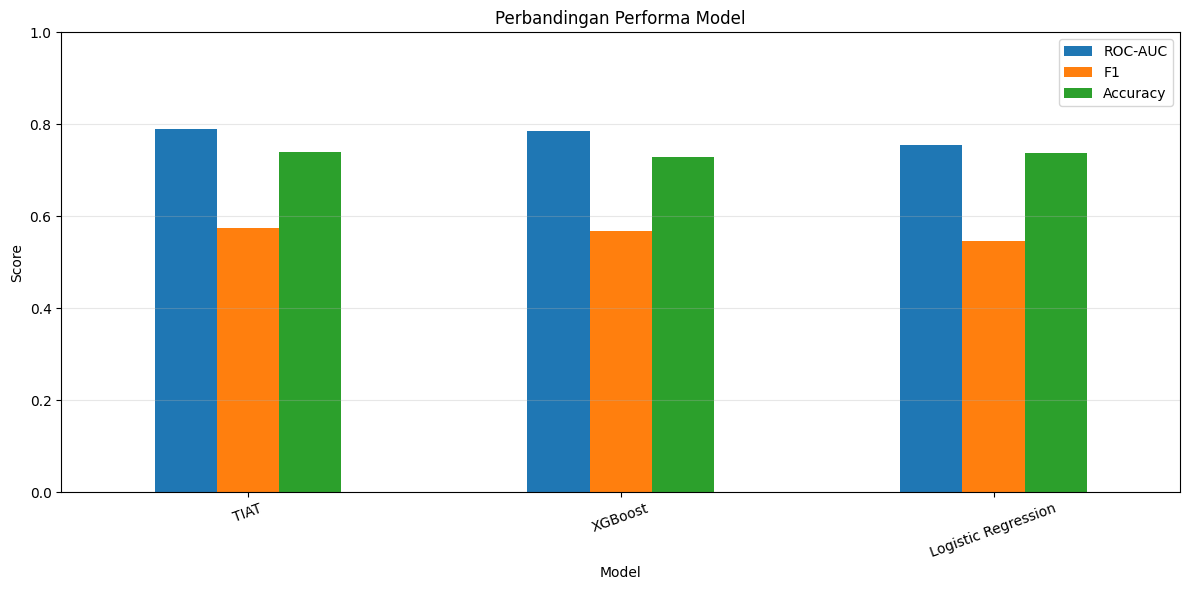

In [ ]:
# Sel 15 — PERBANDINGAN SEMUA MODEL

print("=" * 70)
print("PERBANDINGAN FINAL SEMUA MODEL")
print("=" * 70)

# Tambahkan TIAT

pred_tiat = (prob_te >= 0.5).astype(int)

hasil_model["TIAT"] = {
    "Accuracy": accuracy_score(
        y_te,
        pred_tiat
    ),

    "Precision": precision_score(
        y_te,
        pred_tiat,
        zero_division=0
    ),

    "Recall": recall_score(
        y_te,
        pred_tiat,
        zero_division=0
    ),

    "F1": f1_score(
        y_te,
        pred_tiat,
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_te,
        prob_te
    ),

    "PR-AUC": average_precision_score(
        y_te,
        prob_te
    )
}


# Tabel

df_hasil = pd.DataFrame(
    hasil_model
).T

df_hasil = df_hasil.sort_values(
    "ROC-AUC",
    ascending=False
)

print("\n")
print(df_hasil.round(4))


# Simpan hasil

hasil_path = (
    "/content/drive/MyDrive/"
    "dataset/processed/"
    "perbandingan_model.csv"
)

df_hasil.to_csv(
    hasil_path
)

print(
    f"\n✅ Hasil disimpan di:\n"
    f"{hasil_path}"
)


# VISUALISASI

plt.figure(
    figsize=(12, 6)
)

df_hasil[
    [
        "ROC-AUC",
        "F1",
        "Accuracy"
    ]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Perbandingan Performa Model"
)

plt.ylabel(
    "Score"
)

plt.xlabel(
    "Model"
)

plt.xticks(
    rotation=20
)

plt.ylim(
    0,
    1
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/"
    "dataset/processed/"
    "perbandingan_model.png",
    dpi=200
)

plt.show()

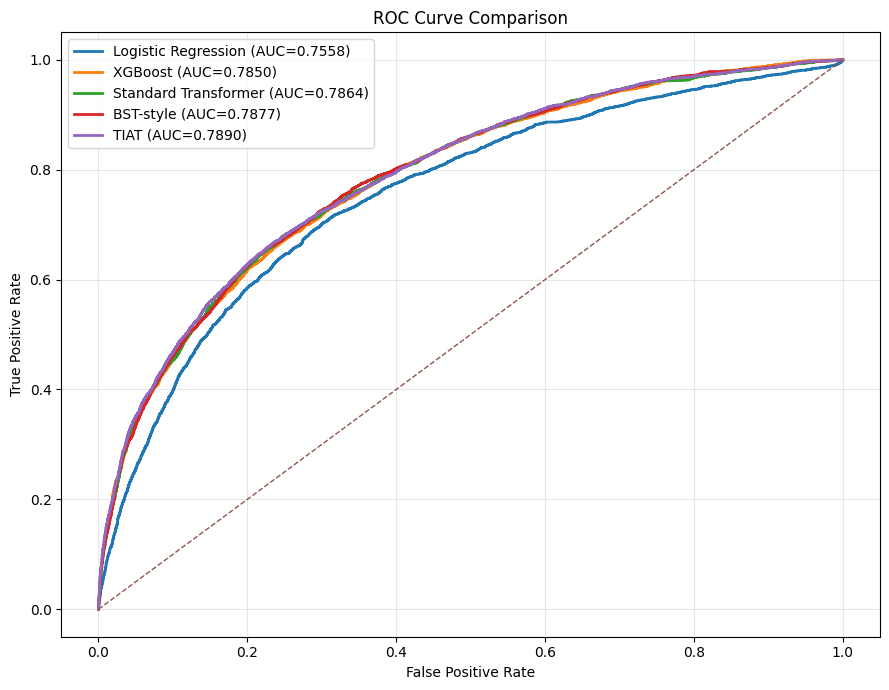

In [ ]:
# SEL 16 — ROC CURVE SEMUA MODEL

probabilitas = {
    "Logistic Regression": prob_lr,
    "XGBoost": prob_xgb,
    "Standard Transformer": prob_std,
    "BST-style": prob_bst,
    "TIAT": prob_te
}

plt.figure(figsize=(9, 7))

for nama, prob in probabilitas.items():

    fpr, tpr, _ = roc_curve(
        y_te,
        prob
    )

    auc = roc_auc_score(
        y_te,
        prob
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{nama} (AUC={auc:.4f})"
    )


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC Curve Comparison"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/"
    "dataset/processed/"
    "roc_comparison.png",
    dpi=200
)

plt.show()